
# Day 4 — Exploratory Data Analysis (EDA)

## Project
NexziByte Predictive Business Intelligence & Growth Engine

## Objective
Explore the cleaned B2B prospect dataset to identify data distributions,
relationships, industry patterns, source performance, and actionable
business findings.

## Input Dataset
`data/clean/Day3_Prospects_Clean.csv`

## Analysis Areas
1. Dataset overview and data quality
2. Univariate analysis
3. Bivariate analysis
4. Industry and prospect classification patterns
5. Source performance
6. Missingness and potential data leakage
7. Business findings and limitations

## Data Integrity Rules
- Preserve the original source CSV unchanged.
- Use the Day 3 cleaned dataset as the input.
- Do not treat the existing Prospect Score as a verified conversion probability.
- Do not invent historical quote, project, revenue, or customer activity.
- Clearly label synthetic data if used.

## Output
EDA notebook and business findings report in the `reports/` folder.


In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project directory
project_dir = Path(r"D:\Nexzibyte Solution\nexzibyte-predictive-bi")

# Load the Day 3 cleaned dataset
clean_path = project_dir / "data" / "clean" / "Day3_Prospects_Clean.csv"

df = pd.read_csv(clean_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully.
Dataset shape: (180, 28)

Column names:
['Company Name', 'Website / Domain', 'Industry / Sub-industry', 'HQ Location (City, State)', 'Founded Year (Standardized)', 'Products/Services', 'Target Customers / B2B or B2C', 'Technology Signals', 'Recent Business Signal', 'Decision-Maker (Name + Title)', 'Source(s) Used', 'Date Verified', 'Employee Count (Numeric)', 'Website Validation', 'Employee Validation', 'Duplicate Flag', 'Data Quality Status', 'Company Size Score', 'B2B Fit Score', 'Technology Signal Score', 'Business Need Score', 'Recent Business Signal Score', 'Decision-Maker Score', 'Prospect Score', 'Prospect Classification', 'ETL Website Format Valid', 'ETL Company Name Unique', 'ETL Score Consistent']


,Company Name,Website / Domain,Industry / Sub-industry,"HQ Location (City, State)",Founded Year (Standardized),Products/Services,Target Customers / B2B or B2C,Technology Signals,Recent Business Signal,Decision-Maker (Name + Title),...,B2B Fit Score,Technology Signal Score,Business Need Score,Recent Business Signal Score,Decision-Maker Score,Prospect Score,Prospect Classification,ETL Website Format Valid,ETL Company Name Unique,ETL Score Consistent
0,Postman,https://www.postman.com,API Development / B2B SaaS,"San Francisco, California, USA; Bengaluru, Kar...",2014,"API Platform, API testing, API governance, API...",B2B / developers and enterprises,"API development, API lifecycle, AI-native API ...",40M+ developers/users and 500K+ organizations;...,Abhinav Asthana — CEO & Co-Founder; Ankit Sobt...,...,20,20,15,15,10,100,High Potential,True,True,True
1,BrowserStack,https://www.browserstack.com,Software Testing / DevOps SaaS,"Dublin, Ireland; founded in Mumbai, India",2011,"Live, App Automate, Automate, Percy, Accessibi...","B2B / developers, QA teams and enterprises","Selenium, Appium, CI/CD, browser automation, A...",50K+ customers; 21 data centers; 2026 AI/testi...,Ritesh Arora — Co-Founder & CEO; Nakul Aggarwa...,...,20,20,5,15,10,90,High Potential,True,True,True
2,Freshworks,https://www.freshworks.com,SaaS / Business Software / AI,"San Mateo, California, USA; founded in Chennai...",2010,"Freshdesk, Freshservice, Freddy AI and custome...",B2B / businesses and enterprises,"AI-first SaaS, AI agents, ITSM, CX",~11% workforce reduction announced May 2026; n...,Dennis Woodside — CEO & President; Girish Math...,...,20,20,15,5,10,90,High Potential,True,True,True
3,Chargebee,https://www.chargebee.com,SaaS / Subscription Billing,"North Bethesda, Maryland, USA; India operations",2011,"Billing, Subscription Management, RevRec, Rece...",B2B / SaaS and subscription businesses,"Python, ML, Spark/SparkML/Hadoop, Docker, micr...",AI subscription management and monetization ex...,Krish Subramanian — CEO & Co-Founder; Saravana...,...,20,7,5,15,10,77,High Potential,True,True,True
4,CleverTap,https://clevertap.com,Customer Engagement SaaS / MarTech,"San Francisco, California, USA; Indian operations",2013,"Customer Data & Analytics, Personalization, Ca...",B2B / consumer brands and enterprises,"Real-time data processing, AI/ML, CDP, Tessera...","2,000+ brands; agentic AI expansion; Tesseract...",Sunil Thomas — Co-Founder & CEO; Anand Jain — ...,...,20,15,15,15,10,95,High Potential,True,True,True


In [2]:

# Day 4: Initial EDA quality checks

print("Dataset shape:", df.shape)

print("\nMissing values per column:")
missing_values = df.isnull().sum()
display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nExact duplicate rows:", df.duplicated().sum())

print(
    "\nDuplicate company names:",
    df["Company Name"].duplicated().sum()
)

print("\nProspect classification counts:")
display(
    df["Prospect Classification"]
    .value_counts(dropna=False)
    .to_frame("Company Count")
)

print("\nData quality status counts:")
display(
    df["Data Quality Status"]
    .value_counts(dropna=False)
    .to_frame("Company Count")
)


Dataset shape: (180, 28)

Missing values per column:


,Missing Count



Exact duplicate rows: 0

Duplicate company names: 0

Prospect classification counts:


,Company Count
Prospect Classification,
High Potential,129
Medium Potential,51



Data quality status counts:


,Company Count
Data Quality Status,
Valid,176
Needs Review,4


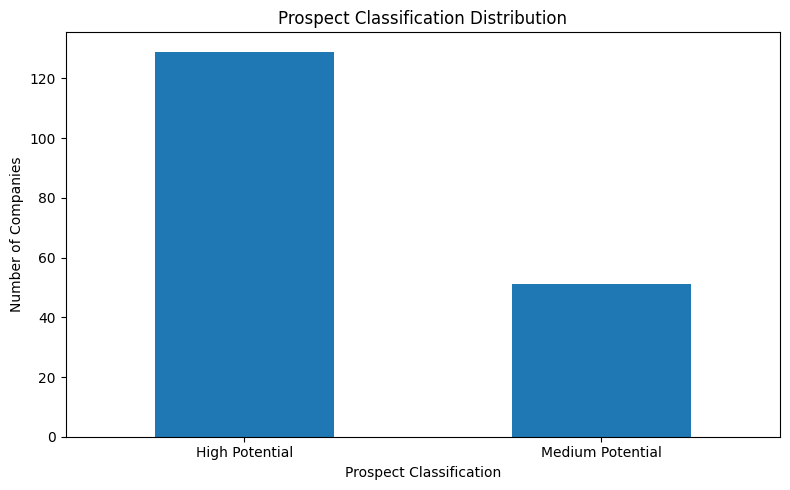

In [3]:

# Day 4: Prospect classification distribution

classification_counts = df["Prospect Classification"].value_counts()

plt.figure(figsize=(8, 5))
classification_counts.plot(kind="bar")

plt.title("Prospect Classification Distribution")
plt.xlabel("Prospect Classification")
plt.ylabel("Number of Companies")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Prospect Score Summary:


,Prospect Score
count,180.000000
mean,79.305556
std,9.525677
min,55.000000
25%,74.000000
50%,80.000000
75%,84.000000
max,100.000000


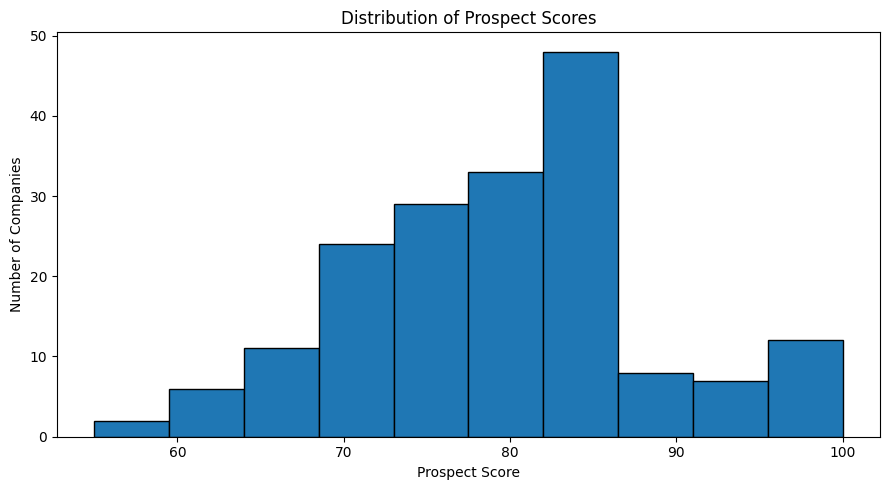

In [9]:

# Day 4: Prospect Score distribution

print("Prospect Score Summary:")
display(df["Prospect Score"].describe().to_frame())

plt.figure(figsize=(9, 5))
plt.hist(df["Prospect Score"], bins=10, edgecolor="black")

plt.title("Distribution of Prospect Scores")
plt.xlabel("Prospect Score")
plt.ylabel("Number of Companies")
plt.tight_layout()
plt.show()


,Mean,Median,Minimum,Maximum
Company Size Score,17.78,20.0,12.0,20.0
B2B Fit Score,17.39,20.0,5.0,20.0
Technology Signal Score,18.38,20.0,5.0,20.0
Business Need Score,13.97,15.0,5.0,15.0
Recent Business Signal Score,6.39,5.0,5.0,15.0
Decision-Maker Score,5.40,4.0,4.0,10.0


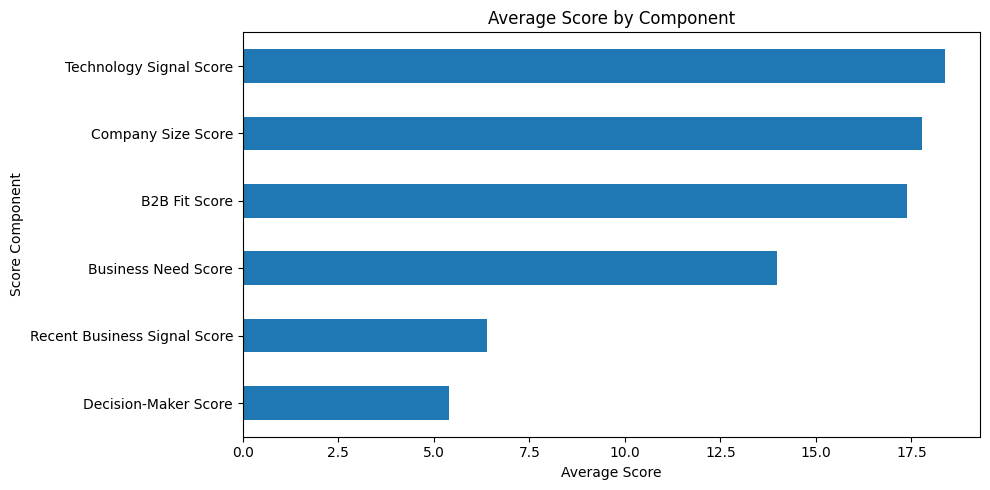

In [5]:

# Day 4: Score component analysis

score_columns = [
    "Company Size Score",
    "B2B Fit Score",
    "Technology Signal Score",
    "Business Need Score",
    "Recent Business Signal Score",
    "Decision-Maker Score"
]

component_summary = df[score_columns].agg(
    ["mean", "median", "min", "max"]
).T

component_summary.columns = [
    "Mean", "Median", "Minimum", "Maximum"
]

display(component_summary.round(2))

plt.figure(figsize=(10, 5))
df[score_columns].mean().sort_values().plot(kind="barh")

plt.title("Average Score by Component")
plt.xlabel("Average Score")
plt.ylabel("Score Component")
plt.tight_layout()
plt.show()


Classification,High Potential,Medium Potential
Company Size Score,17.83,17.65
B2B Fit Score,19.46,12.16
Technology Signal Score,19.37,15.86
Business Need Score,14.50,12.65
Recent Business Signal Score,6.86,5.20
Decision-Maker Score,5.81,4.35


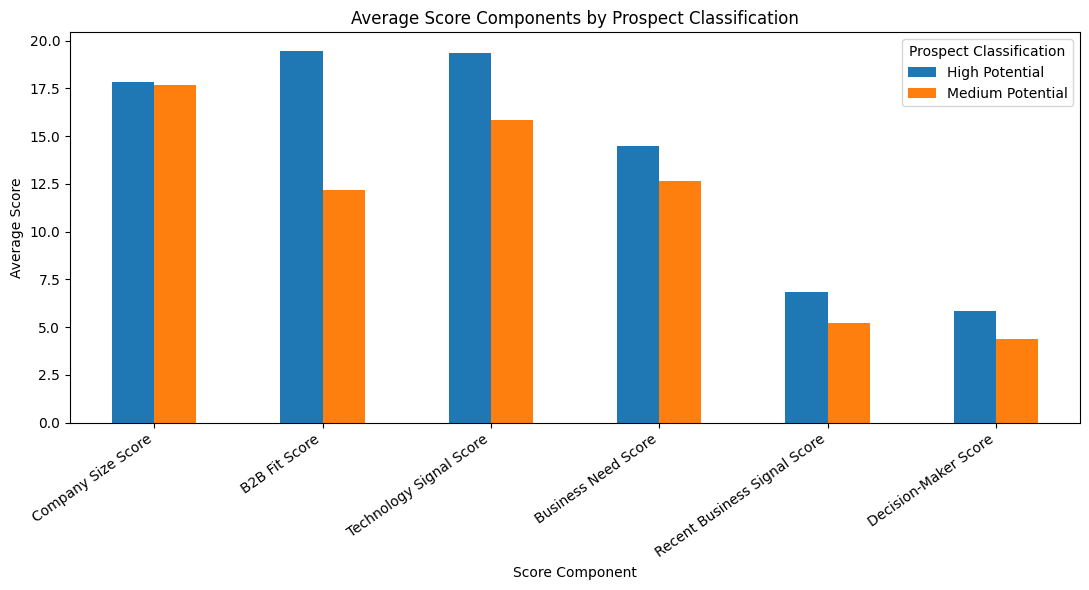

In [6]:

# Day 4: Compare score components by classification

classification_comparison = (
    df.groupby("Prospect Classification")[score_columns]
    .mean()
    .T
)

classification_comparison.columns.name = "Classification"

display(classification_comparison.round(2))

classification_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Average Score Components by Prospect Classification")
plt.xlabel("Score Component")
plt.ylabel("Average Score")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Prospect Classification")
plt.tight_layout()
plt.show()


Distinct industry labels: 19
Industry labels with one company: 15

Top 10 industry labels:


,Industry,Company Count
0,B2B SaaS / Enterprise Software,72
1,AI / ML / GenAI,52
2,FinTech / Payments,39
3,Customer Engagement SaaS / MarTech,2
4,SaaS / Business Software / AI,1
5,API Development / B2B SaaS,1
6,Software Testing / DevOps SaaS,1
7,FinTech / Digital Payments,1
8,FinTech / Brokerage Technology,1
9,SaaS / Subscription Billing,1


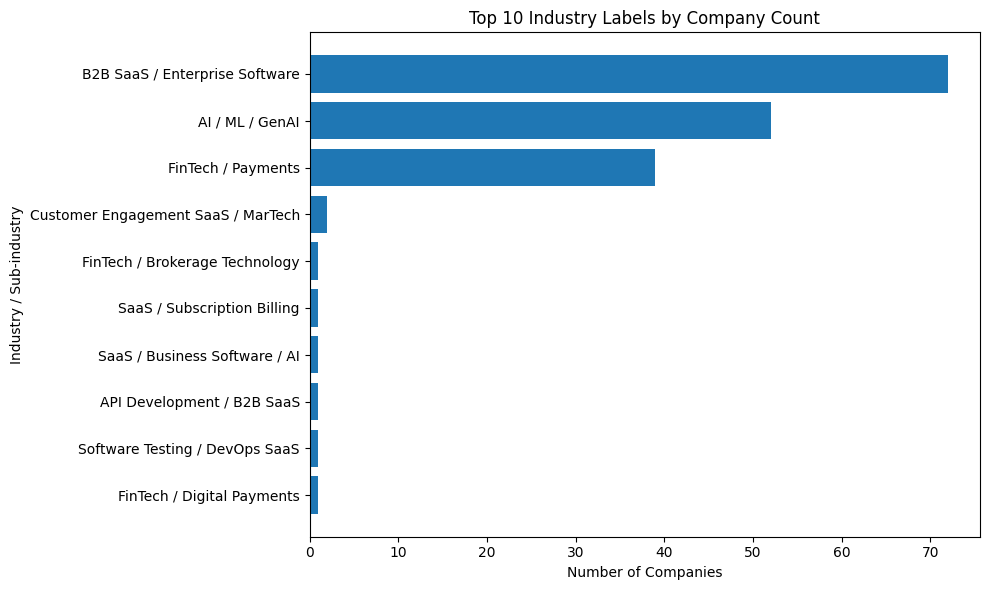

In [7]:

# Day 4: Industry distribution

industry_counts = (
    df["Industry / Sub-industry"]
    .value_counts()
    .rename_axis("Industry")
    .reset_index(name="Company Count")
)

print("Distinct industry labels:", len(industry_counts))
print(
    "Industry labels with one company:",
    int((industry_counts["Company Count"] == 1).sum())
)

print("\nTop 10 industry labels:")
display(industry_counts.head(10))

# Visualize the top 10 industry labels
top_industries = industry_counts.head(10).sort_values("Company Count")

plt.figure(figsize=(10, 6))
plt.barh(
    top_industries["Industry"],
    top_industries["Company Count"]
)

plt.title("Top 10 Industry Labels by Company Count")
plt.xlabel("Number of Companies")
plt.ylabel("Industry / Sub-industry")
plt.tight_layout()
plt.show()


,Company_Count,Average_Prospect_Score,Median_Prospect_Score,Minimum_Score,Maximum_Score
Industry / Sub-industry,,,,,
B2B SaaS / Enterprise Software,72,83.26,83.5,60,100
AI / ML / GenAI,52,74.29,76.0,55,90
FinTech / Payments,39,74.28,77.0,56,84


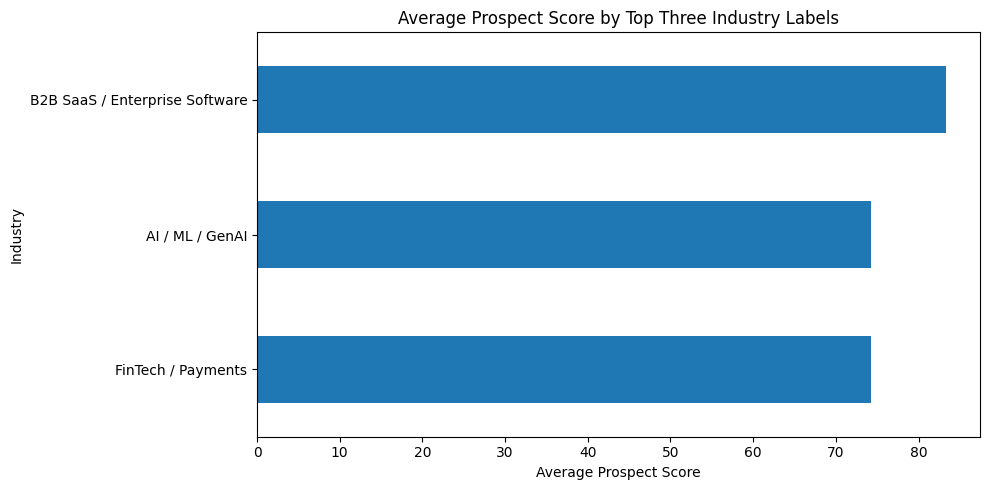

In [10]:

# Day 4: Prospect Score by the three largest industry labels

top_3_industries = industry_counts.head(3)["Industry"].tolist()

industry_score_summary = (
    df[df["Industry / Sub-industry"].isin(top_3_industries)]
    .groupby("Industry / Sub-industry")
    .agg(
        Company_Count=("Prospect Score", "count"),
        Average_Prospect_Score=("Prospect Score", "mean"),
        Median_Prospect_Score=("Prospect Score", "median"),
        Minimum_Score=("Prospect Score", "min"),
        Maximum_Score=("Prospect Score", "max")
    )
    .sort_values("Company_Count", ascending=False)
)

display(industry_score_summary.round(2))

plt.figure(figsize=(10, 5))
industry_score_summary["Average_Prospect_Score"].sort_values().plot(
    kind="barh"
)

plt.title("Average Prospect Score by Top Three Industry Labels")
plt.xlabel("Average Prospect Score")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()


In [11]:

# Day 4: Inspect source information

print("Missing Source(s) Used values:",
      df["Source(s) Used"].isna().sum())

source_counts = (
    df["Source(s) Used"]
    .value_counts(dropna=False)
    .rename_axis("Source")
    .reset_index(name="Company Count")
)

print("Distinct source entries:", df["Source(s) Used"].nunique())

display(source_counts.head(15))


Missing Source(s) Used values: 0
Distinct source entries: 180


,Source,Company Count
0,"Official Postman About, Careers, Press and Con...",1
1,"Official BrowserStack About, Careers and Press...",1
2,"Official Freshworks About, Leadership, Careers...",1
3,Official Chargebee company pages; public Linke...,1
4,"Official CleverTap About, AI, TesseractDB and ...",1
5,Official Zoho About page; Employee count/range...,1
6,Official Razorpay website and About/company in...,1
7,"Official Paytm About, Contact and business pag...",1
8,"Official PhonePe About, Press and Contact page...",1
9,Official PayU company pages; Employee count/ra...,1


In [12]:

# Day 4: Inspect source-description examples

for i, source in enumerate(df["Source(s) Used"].head(5), start=1):
    print(f"\nExample {i}:")
    print(source)



Example 1:
Official Postman About, Careers, Press and Contact pages; public LinkedIn jobs; Employee count/range normalized from public company-size sources; missing values researched; Employee Range completed and normalized to numeric count from public company-size data; Founded year completed from public company sources

Example 2:
Official BrowserStack About, Careers and Press pages; public LinkedIn company data; Employee count/range normalized from public company-size sources; missing values researched; Employee Range completed and normalized to numeric count from public company-size data; Founded year completed from public company sources; Public company contact channel researched/checked 22-08-2026 (BrowserStack)

Example 3:
Official Freshworks About, Leadership, Careers and 2026 company announcement; Employee count/range normalized from public company-size sources; missing values researched; Employee Range completed and normalized to numeric count from public company-size data; 

In [13]:

# Day 4: Inspect scoring relationships and potential leakage

score_columns = [
    "Company Size Score",
    "B2B Fit Score",
    "Technology Signal Score",
    "Business Need Score",
    "Recent Business Signal Score",
    "Decision-Maker Score"
]

# Check whether Prospect Score equals the sum of its components
calculated_score = df[score_columns].sum(axis=1)

print(
    "Rows where Prospect Score differs from component sum:",
    int((df["Prospect Score"] != calculated_score).sum())
)

# Check how Prospect Classification relates to Prospect Score
print("\nClassification by Prospect Score:")
display(
    df.groupby("Prospect Classification")["Prospect Score"]
    .agg(["count", "min", "median", "max"])
)

# Inspect fields that may be unsuitable as predictive features
print("\nScoring-related columns:")
display(df[score_columns + [
    "Prospect Score",
    "Prospect Classification"
]].head())


Rows where Prospect Score differs from component sum: 0

Classification by Prospect Score:


,count,min,median,max
Prospect Classification,,,,
High Potential,129,75,84.0,100
Medium Potential,51,55,69.0,74



Scoring-related columns:


,Company Size Score,B2B Fit Score,Technology Signal Score,Business Need Score,Recent Business Signal Score,Decision-Maker Score,Prospect Score,Prospect Classification
0,20,20,20,15,15,10,100,High Potential
1,20,20,20,5,15,10,90,High Potential
2,20,20,20,15,5,10,90,High Potential
3,20,20,7,5,15,10,77,High Potential
4,20,20,15,15,15,10,95,High Potential


In [14]:

# Day 4: Check availability of business outcome fields

outcome_keywords = [
    "conversion", "converted", "customer", "deal",
    "sales", "revenue", "quote", "proposal",
    "win", "loss", "closed", "opportunity",
    "pipeline", "stage", "date contacted"
]

outcome_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in outcome_keywords)
]

print("Potential business outcome columns:")
print(outcome_columns if outcome_columns else "None found")

print("\nAll available columns:")
for column in df.columns:
    print("-", column)


Potential business outcome columns:
['Target Customers / B2B or B2C']

All available columns:
- Company Name
- Website / Domain
- Industry / Sub-industry
- HQ Location (City, State)
- Founded Year (Standardized)
- Products/Services
- Target Customers / B2B or B2C
- Technology Signals
- Recent Business Signal
- Decision-Maker (Name + Title)
- Source(s) Used
- Date Verified
- Employee Count (Numeric)
- Website Validation
- Employee Validation
- Duplicate Flag
- Data Quality Status
- Company Size Score
- B2B Fit Score
- Technology Signal Score
- Business Need Score
- Recent Business Signal Score
- Decision-Maker Score
- Prospect Score
- Prospect Classification
- ETL Website Format Valid
- ETL Company Name Unique
- ETL Score Consistent


## Day 4 — Preliminary EDA Findings

### 1. Dataset Overview
- Records analyzed: 180 companies
- Columns: 28
- Missing values: 0
- Exact duplicate rows: 0
- Duplicate company names: 0
- Data quality status: 176 Valid and 4 Needs Review

### 2. Prospect Classification
- High Potential: 129 companies (71.7%)
- Medium Potential: 51 companies (28.3%)

These classifications reflect the existing scoring system and are not verified conversion probabilities.

### 3. Prospect Score Distribution
- Mean: 79.31
- Median: 80
- Minimum: 55
- Maximum: 100
- Interquartile range: 74–84

### 4. Score Component Analysis
Technology Signal Score has the highest mean (18.38/20). Recent Business Signal Score averages 6.39/15, while Decision-Maker Score averages 5.40/10. Component scales differ, so raw means should not be compared without considering their maximum values.

### 5. Industry Distribution
- Distinct industry labels: 19
- Labels with one company: 15
- B2B SaaS / Enterprise Software: 72 companies
- AI / ML / GenAI: 52 companies
- FinTech / Payments: 39 companies

The three largest labels account for 163 companies (90.6%). Industry standardization may be beneficial, subject to review.

### 6. Industry Score Comparison
- B2B SaaS / Enterprise Software: average 83.26
- AI / ML / GenAI: average 74.29
- FinTech / Payments: average 74.28

These results describe existing scores, not observed sales performance.

### 7. Source Information
All 180 records contain source descriptions, but every description is distinct and may include multiple source types. Standardization is needed before defensible source-level comparisons.

### 8. Scoring Consistency and Leakage Risk
All 180 Prospect Scores equal the sum of their six component scores. High Potential scores range from 75–100 and Medium Potential scores from 55–74. Using the score or its components to predict a classification derived from those same scores would introduce target leakage.

### 9. Business Outcome Data Limitations
The available dataset does not contain explicit historical conversion outcomes, quote results, revenue history, or customer-retention records. Consequently, lead conversion prediction, quote win prediction, revenue forecasting, churn prediction, and customer lifetime value modeling cannot be validated from this dataset alone.

### 10. Preliminary Conclusion
The current dataset supports descriptive prospect analysis, score distribution analysis, and limited industry comparisons. Additional historical business outcome data is required for validated predictive models and revenue-related analyses.

### Status
Preliminary EDA findings documented. Complete remaining Day 4 analyses and validation before marking the day signed off.

In [15]:

# Day 4: Inspect records requiring data-quality review

review_columns = [
    "Company Name",
    "Website / Domain",
    "Website Validation",
    "Employee Validation",
    "Duplicate Flag",
    "Data Quality Status",
    "ETL Website Format Valid",
    "ETL Company Name Unique",
    "ETL Score Consistent"
]

review_records = df.loc[
    df["Data Quality Status"] == "Needs Review",
    review_columns
]

print("Records requiring review:", len(review_records))
display(review_records)


Records requiring review: 4


,Company Name,Website / Domain,Website Validation,Employee Validation,Duplicate Flag,Data Quality Status,ETL Website Format Valid,ETL Company Name Unique,ETL Score Consistent
9,PayU India,https://payu.in,Valid,Needs Review — numeric count present but no de...,Unique,Needs Review,True,True,True
32,Wingify,https://wingify.com,Valid,Needs Review — numeric count present but no de...,Unique,Needs Review,True,True,True
36,Facilio,https://facilio.com,Valid,Needs Review — numeric count present but no de...,Unique,Needs Review,True,True,True
37,SpotDraft,https://www.spotdraft.com,Valid,Needs Review — numeric count present but no de...,Unique,Needs Review,True,True,True


In [16]:
classification_comparison = (
    df.groupby("Prospect Classification")[
        [
            "Company Size Score",
            "B2B Fit Score",
            "Technology Signal Score",
            "Business Need Score",
            "Recent Business Signal Score",
            "Decision-Maker Score",
            "Prospect Score",
        ]
    ]
    .mean()
    .round(2)
)

display(classification_comparison)

,Company Size Score,B2B Fit Score,Technology Signal Score,Business Need Score,Recent Business Signal Score,Decision-Maker Score,Prospect Score
Prospect Classification,,,,,,,
High Potential,17.83,19.46,19.37,14.50,6.86,5.81,83.83
Medium Potential,17.65,12.16,15.86,12.65,5.20,4.35,67.86


In [17]:
industry_summary = (
    df.groupby("Industry / Sub-industry")["Prospect Score"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("count", ascending=False)
)

display(industry_summary)

,count,mean,median,min,max
Industry / Sub-industry,,,,,
B2B SaaS / Enterprise Software,72,83.26,83.5,60,100
AI / ML / GenAI,52,74.29,76.0,55,90
FinTech / Payments,39,74.28,77.0,56,84
Customer Engagement SaaS / MarTech,2,95.00,95.0,95,95
API Development / B2B SaaS,1,100.00,100.0,100,100
B2B Commerce / Supply Chain,1,95.00,95.0,95,95
CRM / Sales & Marketing Automation SaaS,1,94.00,94.0,94,94
Cloud Data Protection / Cybersecurity,1,85.00,85.0,85,85
Developer Infrastructure / Data APIs,1,82.00,82.0,82,82


In [18]:
print("Date Verified summary:")
print("Unique dates:", df["Date Verified"].nunique())
print("Earliest date:", df["Date Verified"].min())
print("Latest date:", df["Date Verified"].max())

display(
    df["Date Verified"]
    .value_counts(dropna=False)
    .sort_index()
)


Date Verified summary:
Unique dates: 1
Earliest date: 2026-08-22
Latest date: 2026-08-22


Date Verified
2026-08-22    180
Name: count, dtype: int64

In [19]:
keywords = [
    "pipeline", "stage", "status", "created", "lead",
    "quote", "proposal", "win", "loss", "conversion",
    "revenue", "customer", "project", "effort",
    "cost", "aging", "close", "churn"
]

for keyword in keywords:
    matches = [
        column for column in df.columns
        if keyword.lower() in column.lower()
    ]
    print(f"{keyword}: {matches}")

pipeline: []
stage: []
status: ['Data Quality Status']
created: []
lead: []
quote: []
proposal: []
win: []
loss: []
conversion: []
revenue: []
customer: ['Target Customers / B2B or B2C']
project: []
effort: []
cost: []
aging: []
close: []
churn: []


In [20]:

# Day 5 — Feature Availability Audit

feature_audit = pd.DataFrame({
    "Feature Group": [
        "Company size",
        "Industry",
        "B2B fit",
        "Technology signals",
        "Business need",
        "Recent business signal",
        "Decision-maker",
        "Verification date",
        "Pipeline recency",
        "Engagement frequency",
        "Conversion outcome",
        "Revenue / project cost"
    ],
    "Available Columns": [
        "Employee Count (Numeric), Company Size Score",
        "Industry / Sub-industry",
        "Target Customers / B2B or B2C, B2B Fit Score",
        "Technology Signals, Technology Signal Score",
        "Business Need Score",
        "Recent Business Signal, Recent Business Signal Score",
        "Decision-Maker (Name + Title), Decision-Maker Score",
        "Date Verified",
        "Not available",
        "Not available",
        "Not available",
        "Not available"
    ],
    "Day 5 Status": [
        "Available",
        "Available",
        "Available",
        "Available",
        "Available",
        "Available; historical trend unavailable",
        "Available",
        "One shared date only",
        "Blocked: no event dates",
        "Blocked: no engagement history",
        "Blocked: no observed outcome label",
        "Blocked: no operational records"
    ]
})

display(feature_audit)


,Feature Group,Available Columns,Day 5 Status
0,Company size,"Employee Count (Numeric), Company Size Score",Available
1,Industry,Industry / Sub-industry,Available
2,B2B fit,"Target Customers / B2B or B2C, B2B Fit Score",Available
3,Technology signals,"Technology Signals, Technology Signal Score",Available
4,Business need,Business Need Score,Available
5,Recent business signal,"Recent Business Signal, Recent Business Signal...",Available; historical trend unavailable
6,Decision-maker,"Decision-Maker (Name + Title), Decision-Maker ...",Available
7,Verification date,Date Verified,One shared date only
8,Pipeline recency,Not available,Blocked: no event dates
9,Engagement frequency,Not available,Blocked: no engagement history
